In [1]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier 
from sklearn.linear_model import LogisticRegression 
from sklearn.metrics import accuracy_score 

In [2]:
df = pd.read_csv("brfss.csv")
df

,CHD_OR_MI,SEX,AGE,HEALTH,PHYSICAL_HEALTH,STROKE,BRONCHITIS,KIDNEY_DISEASE,DIABETES,ARTHRITIS,BMI,DIFFICULTY_WALKING,SMOKE,ETHNICITY,SLEEP,ASTHMA,DEPRESSION
0,2.0,2.0,80.0,2.0,1.0,2.0,2.0,2.0,1.0,2.0,2918.545455,2.0,2.0,1.0,8.0,2.0,2.0
1,2.0,2.0,80.0,1.0,1.0,2.0,2.0,2.0,3.0,2.0,2657.000000,2.0,2.0,1.0,6.0,2.0,2.0
2,2.0,2.0,56.0,2.0,2.0,2.0,2.0,2.0,3.0,2.0,2561.000000,2.0,2.0,1.0,5.0,2.0,2.0
3,2.0,2.0,73.0,1.0,1.0,2.0,2.0,2.0,3.0,1.0,2330.000000,2.0,1.0,1.0,7.0,1.0,2.0
4,2.0,2.0,43.0,4.0,2.0,2.0,2.0,2.0,3.0,2.0,2177.000000,2.0,2.0,1.0,9.0,2.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
415694,2.0,2.0,19.0,3.0,1.0,2.0,2.0,2.0,3.0,2.0,2563.000000,2.0,2.0,2.0,6.0,1.0,1.0
415695,2.0,2.0,51.0,1.0,2.0,2.0,2.0,2.0,3.0,2.0,2866.000000,2.0,2.0,2.0,7.0,2.0,2.0
415696,2.0,2.0,65.0,5.0,3.0,2.0,2.0,2.0,3.0,2.0,1723.000000,2.0,1.0,2.0,5.0,2.0,2.0
415697,1.0,1.0,73.0,2.0,1.0,2.0,2.0,2.0,3.0,2.0,3255.000000,2.0,2.0,2.0,5.0,1.0,2.0


In [3]:
df.describe()

,CHD_OR_MI,SEX,AGE,HEALTH,PHYSICAL_HEALTH,STROKE,BRONCHITIS,KIDNEY_DISEASE,DIABETES,ARTHRITIS,BMI,DIFFICULTY_WALKING,SMOKE,ETHNICITY,SLEEP,ASTHMA,DEPRESSION
count,415699.000000,415699.000000,415699.000000,415699.000000,415699.000000,415699.000000,415699.000000,415699.000000,415699.000000,415699.000000,415699.000000,415699.000000,415699.000000,415699.000000,415699.000000,415699.000000,415699.000000
mean,1.912985,1.529453,54.609816,2.530254,1.505782,1.959278,1.923728,1.955951,2.746836,1.665556,2849.856697,1.857455,1.633769,1.700974,7.025680,1.851977,1.796670
std,0.281857,0.499132,17.640252,1.039393,0.711275,0.197645,0.265432,0.205204,0.707263,0.471796,623.509372,0.349609,0.481774,1.429593,1.478263,0.355123,0.402476
min,1.000000,1.000000,18.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1202.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,2.000000,1.000000,40.000000,2.000000,1.000000,2.000000,2.000000,2.000000,3.000000,1.000000,2437.000000,2.000000,1.000000,1.000000,6.000000,2.000000,2.000000
50%,2.000000,2.000000,57.000000,2.000000,1.000000,2.000000,2.000000,2.000000,3.000000,2.000000,2746.000000,2.000000,2.000000,1.000000,7.000000,2.000000,2.000000
75%,2.000000,2.000000,69.000000,3.000000,2.000000,2.000000,2.000000,2.000000,3.000000,2.000000,3141.000000,2.000000,2.000000,1.000000,8.000000,2.000000,2.000000
max,2.000000,2.000000,80.000000,5.000000,3.000000,2.000000,2.000000,2.000000,4.000000,2.000000,9934.000000,2.000000,2.000000,6.000000,24.000000,2.000000,2.000000


In [4]:
df['CHD_OR_MI'] = df['CHD_OR_MI'].replace({2:0})
df['CHD_OR_MI'].value_counts()

CHD_OR_MI
0.0    379527
1.0     36172
Name: count, dtype: int64

In [5]:
category_counts = df['CHD_OR_MI'].value_counts()

# Calcular el porcentaje de cada categoría
category_percentages = (category_counts / category_counts.sum()) * 100

# Mostrar los porcentajes
print(category_percentages)

CHD_OR_MI
0.0    91.298512
1.0     8.701488
Name: count, dtype: float64


In [6]:
df['CHD_OR_MI'].describe()

count    415699.000000
mean          0.087015
std           0.281857
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max           1.000000
Name: CHD_OR_MI, dtype: float64

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 415699 entries, 0 to 415698
Data columns (total 17 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   CHD_OR_MI           415699 non-null  float64
 1   SEX                 415699 non-null  float64
 2   AGE                 415699 non-null  float64
 3   HEALTH              415699 non-null  float64
 4   PHYSICAL_HEALTH     415699 non-null  float64
 5   STROKE              415699 non-null  float64
 6   BRONCHITIS          415699 non-null  float64
 7   KIDNEY_DISEASE      415699 non-null  float64
 8   DIABETES            415699 non-null  float64
 9   ARTHRITIS           415699 non-null  float64
 10  BMI                 415699 non-null  float64
 11  DIFFICULTY_WALKING  415699 non-null  float64
 12  SMOKE               415699 non-null  float64
 13  ETHNICITY           415699 non-null  float64
 14  SLEEP               415699 non-null  float64
 15  ASTHMA              415699 non-nul

df['SEX'] = df['SEX'].replace({1: 'A', 2: 'B'})
df['HEALTH'] = df['HEALTH'].replace({1: 'A', 2: 'B', 3:'C', 4:'D', 5:'E'})
df['PHYSICAL_HEALTH'] = df['PHYSICAL_HEALTH'].replace({1: 'A', 2: 'B', 3:'C'})
df['STROKE'] = df['STROKE'].replace({1: 'A', 2: 'B'})
df['BRONCHITIS'] = df['BRONCHITIS'].replace({1: 'A', 2: 'B'})
df['KIDNEY_DISEASE'] = df['KIDNEY_DISEASE'].replace({1: 'A', 2: 'B'})
df['DIABETES'] = df['DIABETES'].replace({1: 'A', 2: 'B', 3:'C', 4:'D'})
df['ARTHRITIS'] = df['ARTHRITIS'].replace({1: 'A', 2: 'B'})
df['DIFFICULTY_WALKING'] = df['DIFFICULTY_WALKING'].replace({1: 'A', 2: 'B'})
df['SMOKE'] = df['SMOKE'].replace({1: 'A', 2: 'B'})
df['ETHNICITY'] = df['ETHNICITY'].replace({1: 'A', 2: 'B', 3:'C', 4:'D', 5:'E', 6:'D'})
df['ASTHMA'] = df['ASTHMA'].replace({1: 'A', 2: 'B'})
df['DEPRESSION'] = df['DEPRESSION'].replace({1: 'A', 2: 'B'})

from sentence_transformers import SentenceTransformer
def compile_text(x):

    text =  f"""SEX: {x['SEX']},  
                HEALTH: {x['HEALTH']}, 
                PHYSICAL_HEALTH: {x['PHYSICAL_HEALTH']}, 
                STROKE: {x['STROKE']}, 
                BRONCHITIS: {x['BRONCHITIS']}, 
                KIDNEY_DISEASE: {x['KIDNEY_DISEASE']}, 
                DIABETES: {x['DIABETES']}, 
                ARTHRITIS: {x['ARTHRITIS']}, 
                DIFFICULTY_WALKING: {x['DIFFICULTY_WALKING']}
                SMOKE: {x['SMOKE']}, 
                ETHNICITY: {x['ETHNICITY']}, 
                ASTHMA: {x['ASTHMA']}, 
                DEPRESSION: {x['DEPRESSION']}
            """

    return text

sentences = df.apply(lambda x: compile_text(x), axis=1).tolist()
model = SentenceTransformer(r"sentence-transformers/paraphrase-MiniLM-L6-v2")
output = model.encode(sentences=sentences,
         show_progress_bar=True,
         normalize_embeddings=True)

df2 = pd.DataFrame(output)
df2

In [8]:
df

,CHD_OR_MI,SEX,AGE,HEALTH,PHYSICAL_HEALTH,STROKE,BRONCHITIS,KIDNEY_DISEASE,DIABETES,ARTHRITIS,BMI,DIFFICULTY_WALKING,SMOKE,ETHNICITY,SLEEP,ASTHMA,DEPRESSION
0,0.0,2.0,80.0,2.0,1.0,2.0,2.0,2.0,1.0,2.0,2918.545455,2.0,2.0,1.0,8.0,2.0,2.0
1,0.0,2.0,80.0,1.0,1.0,2.0,2.0,2.0,3.0,2.0,2657.000000,2.0,2.0,1.0,6.0,2.0,2.0
2,0.0,2.0,56.0,2.0,2.0,2.0,2.0,2.0,3.0,2.0,2561.000000,2.0,2.0,1.0,5.0,2.0,2.0
3,0.0,2.0,73.0,1.0,1.0,2.0,2.0,2.0,3.0,1.0,2330.000000,2.0,1.0,1.0,7.0,1.0,2.0
4,0.0,2.0,43.0,4.0,2.0,2.0,2.0,2.0,3.0,2.0,2177.000000,2.0,2.0,1.0,9.0,2.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
415694,0.0,2.0,19.0,3.0,1.0,2.0,2.0,2.0,3.0,2.0,2563.000000,2.0,2.0,2.0,6.0,1.0,1.0
415695,0.0,2.0,51.0,1.0,2.0,2.0,2.0,2.0,3.0,2.0,2866.000000,2.0,2.0,2.0,7.0,2.0,2.0
415696,0.0,2.0,65.0,5.0,3.0,2.0,2.0,2.0,3.0,2.0,1723.000000,2.0,1.0,2.0,5.0,2.0,2.0
415697,1.0,1.0,73.0,2.0,1.0,2.0,2.0,2.0,3.0,2.0,3255.000000,2.0,2.0,2.0,5.0,1.0,2.0


In [9]:
X = df.loc[:, df.columns!="CHD_OR_MI"]
y = df["CHD_OR_MI"]

In [10]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size = 0.2,stratify=y, random_state=1)

In [11]:
columns = X.columns.values

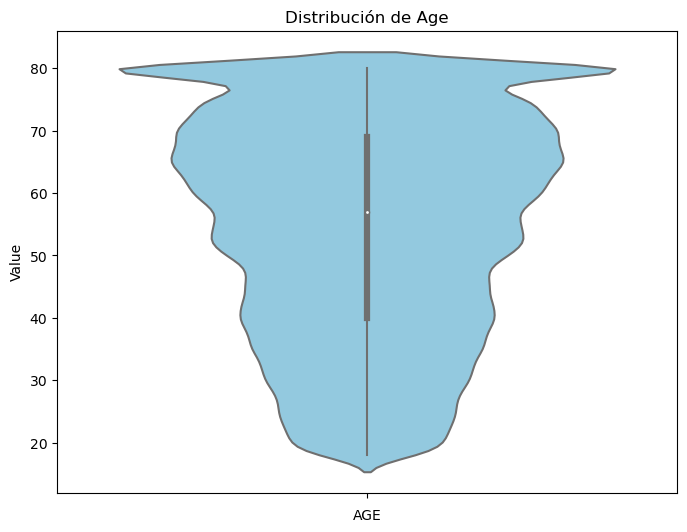

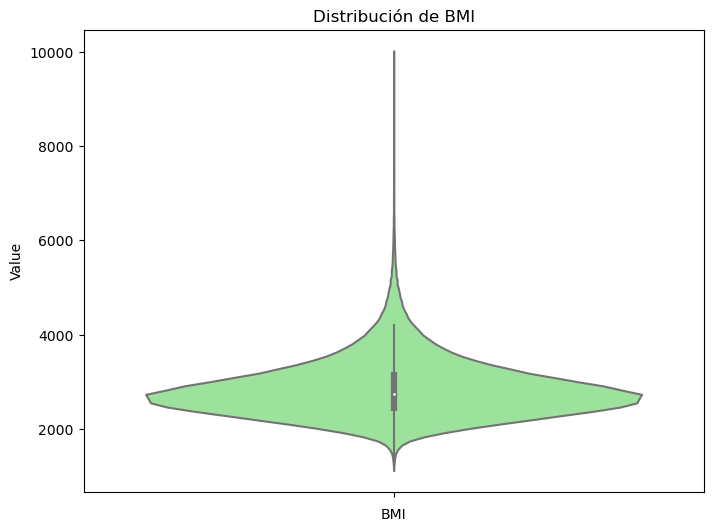

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 6))
sns.violinplot(y=df['AGE'], inner='box', color='skyblue')
plt.title('Distribución de Age')
plt.xlabel('AGE')
plt.ylabel('Value')
plt.show()

# Crear un gráfico de violín para la variable BMI
plt.figure(figsize=(8, 6))
sns.violinplot(y=df['BMI'], inner='box', color='lightgreen')
plt.title('Distribución de BMI')
plt.xlabel('BMI')
plt.ylabel('Value')
plt.show()

## Clasification

In [12]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report

### Class Weighting

In [13]:
class_weights = {0: 1, 1: 6}
class_weights

{0: 1, 1: 6}

### RF

In [14]:
from sklearn.ensemble import RandomForestClassifier
import time
rfc = RandomForestClassifier(n_estimators=200, max_leaf_nodes = 15, max_depth=10, 
                             n_jobs=-1, class_weight = class_weights, random_state = 1)
start_time = time.time()
rfc.fit(X_train, y_train)
end_time = time.time()
training_time = end_time - start_time
print(f'Tiempo de entrenamiento: {training_time:.2f} segundos')

Tiempo de entrenamiento: 19.09 segundos


              precision    recall  f1-score   support

         0.0       0.96      0.85      0.90     75906
         1.0       0.28      0.61      0.39      7234

    accuracy                           0.83     83140
   macro avg       0.62      0.73      0.64     83140
weighted avg       0.90      0.83      0.86     83140

Especificidad: 0.8527916106763629


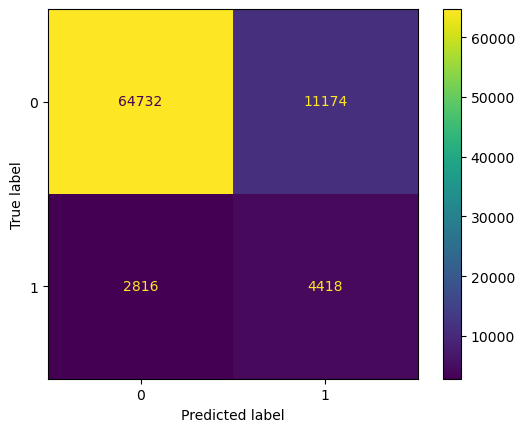

In [15]:
y_pred = rfc.predict(X_test)
conf_mat=confusion_matrix(y_test,y_pred)
cm_display = ConfusionMatrixDisplay(conf_mat).plot()
print(classification_report(y_test,y_pred))
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
specificity = tn / (tn + fp)
print("Especificidad:", specificity)

### XGB

In [16]:
from xgboost import XGBClassifier
cxgb = XGBClassifier(n_estimators = 200, min_samples_leaf = 15, max_features = None, learning_rate = 0.05, 
                      max_depth = 10, random_state = 1, n_jobs = -1, scale_pos_weight=class_weights[1])
start_time = time.time()
cxgb.fit(X_train, y_train)
end_time = time.time()
training_time = end_time - start_time
print(f'Tiempo de entrenamiento: {training_time:.2f} segundos')

C:\Users\alecv\anaconda3\envs\tf2\lib\site-packages\xgboost\core.py:160: UserWarning: [16:54:05] WARNING: C:\b\abs_0fh_d4x2ng\croot\xgboost-split_1713973188995\work\cpp_src\src\learner.cc:742: 
Parameters: { "min_samples_leaf" } are not used.

  warnings.warn(smsg, UserWarning)


Tiempo de entrenamiento: 7.23 segundos


              precision    recall  f1-score   support

         0.0       0.96      0.86      0.90     75906
         1.0       0.28      0.59      0.38      7234

    accuracy                           0.83     83140
   macro avg       0.62      0.72      0.64     83140
weighted avg       0.90      0.83      0.86     83140

Especificidad: 0.8573630543040076


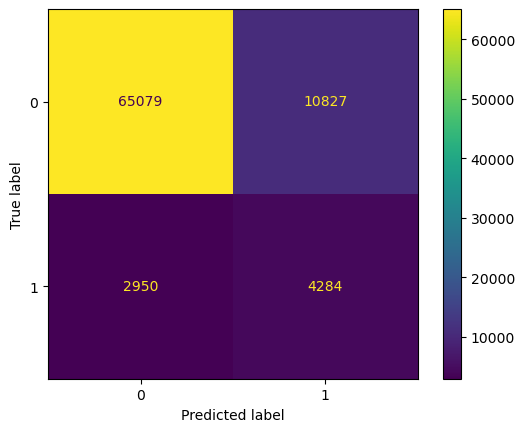

In [62]:
y_pred = cxgb.predict(X_test)
conf_mat=confusion_matrix(y_test,y_pred)
cm_display = ConfusionMatrixDisplay(conf_mat).plot()
print(classification_report(y_test,y_pred))
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
specificity = tn / (tn + fp)
print("Especificidad:", specificity)

### LGBM

[LightGBM] [Warning] min_data_in_leaf is set with min_child_samples=20, will be overridden by min_samples_leaf=15. Current value: min_data_in_leaf=15
[LightGBM] [Warning] Accuracy may be bad since you didn't explicitly set num_leaves OR 2^max_depth > num_leaves. (num_leaves=31).
[LightGBM] [Warning] min_data_in_leaf is set with min_child_samples=20, will be overridden by min_samples_leaf=15. Current value: min_data_in_leaf=15
[LightGBM] [Warning] Accuracy may be bad since you didn't explicitly set num_leaves OR 2^max_depth > num_leaves. (num_leaves=31).
[LightGBM] [Info] Number of positive: 28938, number of negative: 303621
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.016066 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 392
[LightGBM] [Info] Number of data points in the train set: 332559, number of used features: 16
[LightGBM] [Inf

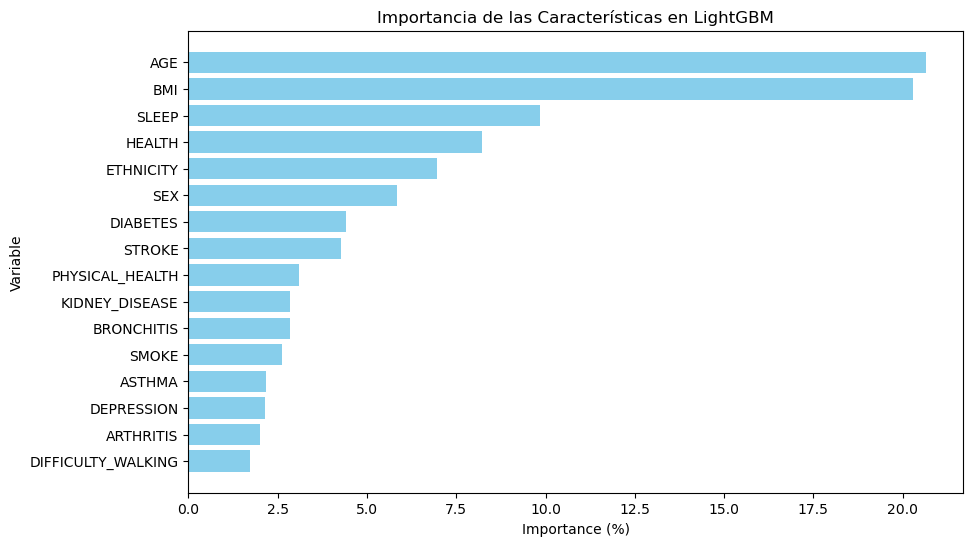

In [20]:
from lightgbm import LGBMClassifier
lgbm = LGBMClassifier(n_estimators = 200, min_samples_leaf = 15, max_features = None, learning_rate = 0.05, 
                          max_depth = 10, random_state = 1, n_jobs = -1, scale_pos_weight=class_weights[1])
lgbm.fit(X_train, y_train)
# Obtener la importancia de las características
importance = lgbm.feature_importances_
feature_names = X_train.columns

# Crear un DataFrame con las características y su importancia
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
})

# Calcular el porcentaje de importancia
importance_df['Importance (%)'] = (importance_df['Importance'] / importance_df['Importance'].sum()) * 100

# Ordenar las características por importancia
importance_df = importance_df.sort_values(by='Importance (%)', ascending=False)

# Mostrar la importancia de las características
print(importance_df)

# Graficar la importancia de las características
plt.figure(figsize=(10, 6))
plt.barh(importance_df['Feature'], importance_df['Importance (%)'], color='skyblue')
plt.xlabel('Importance (%)')
plt.ylabel('Variable')
plt.title('Importancia de las Características en LightGBM')
plt.gca().invert_yaxis()  # Invertir el eje y para que la característica más importante esté arriba
plt.show()

[LightGBM] [Warning] min_data_in_leaf is set with min_child_samples=20, will be overridden by min_samples_leaf=15. Current value: min_data_in_leaf=15
[LightGBM] [Warning] Accuracy may be bad since you didn't explicitly set num_leaves OR 2^max_depth > num_leaves. (num_leaves=31).
              precision    recall  f1-score   support

         0.0       0.96      0.83      0.89     75906
         1.0       0.27      0.66      0.39      7234

    accuracy                           0.82     83140
   macro avg       0.62      0.75      0.64     83140
weighted avg       0.90      0.82      0.85     83140

Especificidad: 0.8324374884725845


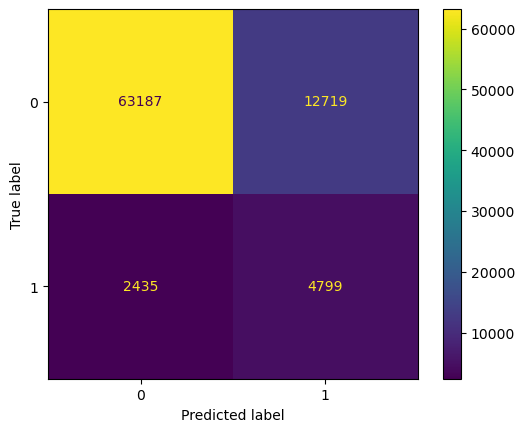

In [19]:
y_pred = lgbm.predict(X_test)
conf_mat=confusion_matrix(y_test,y_pred)
cm_display = ConfusionMatrixDisplay(conf_mat).plot()
print(classification_report(y_test,y_pred))
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
specificity = tn / (tn + fp)
print("Especificidad:", specificity)

## ADASYN

In [65]:
from imblearn.over_sampling import ADASYN
ada = ADASYN(n_jobs=-1, random_state = 1, n_neighbors = 21)
X_train_balanced, y_train_balanced = ada.fit_resample(X_train, y_train)

C:\Users\alecv\anaconda3\envs\tf2\lib\site-packages\imblearn\over_sampling\_adasyn.py:156: FutureWarning: The parameter `n_jobs` has been deprecated in 0.10 and will be removed in 0.12. You can pass an nearest neighbors estimator where `n_jobs` is already set instead.
  warnings.warn(


In [66]:
rfc2 = RandomForestClassifier(n_estimators = 50, max_leaf_nodes = 15, max_depth = 10, 
                             n_jobs=-1, random_state = 1)
rfc2.fit(X_train_balanced, y_train_balanced)

RandomForestClassifier(max_depth=10, max_leaf_nodes=15, n_estimators=50,
                       n_jobs=-1, random_state=1)

              precision    recall  f1-score   support

         0.0       0.95      0.89      0.92     75906
         1.0       0.29      0.47      0.36      7234

    accuracy                           0.86     83140
   macro avg       0.62      0.68      0.64     83140
weighted avg       0.89      0.86      0.87     83140

Especificidad: 0.892630358601428


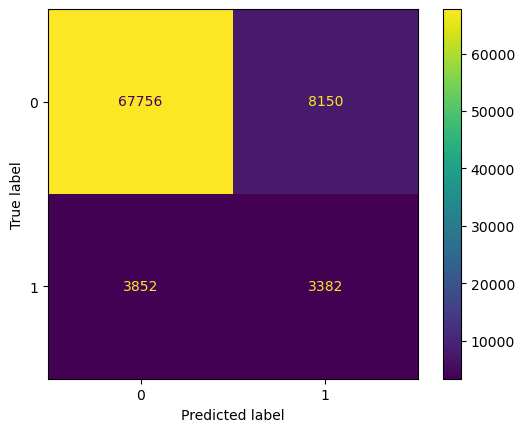

In [67]:
y_pred = rfc2.predict(X_test)
conf_mat=confusion_matrix(y_test,y_pred)
cm_display = ConfusionMatrixDisplay(conf_mat).plot()
print(classification_report(y_test,y_pred))
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
specificity = tn / (tn + fp)
print("Especificidad:", specificity)

In [68]:
cxgb2 = XGBClassifier(n_estimators = 10, min_samples_leaf = 20, max_depth = 10, random_state = 1, n_jobs = -1, 
                     learning_rate = 0.001, max_features = None)
cxgb2.fit(X_train_balanced, y_train_balanced)

C:\Users\alecv\anaconda3\envs\tf2\lib\site-packages\xgboost\core.py:160: UserWarning: [21:18:47] WARNING: C:\b\abs_0fh_d4x2ng\croot\xgboost-split_1713973188995\work\cpp_src\src\learner.cc:742: 
Parameters: { "min_samples_leaf" } are not used.

  warnings.warn(smsg, UserWarning)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.001, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=10, max_features=None,
              max_leaves=None, min_child_weight=None, min_samples_leaf=20,
              missing=nan, monotone_constraints=None, multi_strategy=None,
              n_estimators=10, n_jobs=-1, ...)

              precision    recall  f1-score   support

         0.0       0.94      0.93      0.93     75906
         1.0       0.33      0.38      0.35      7234

    accuracy                           0.88     83140
   macro avg       0.64      0.65      0.64     83140
weighted avg       0.89      0.88      0.88     83140

Especificidad: 0.926488024662082


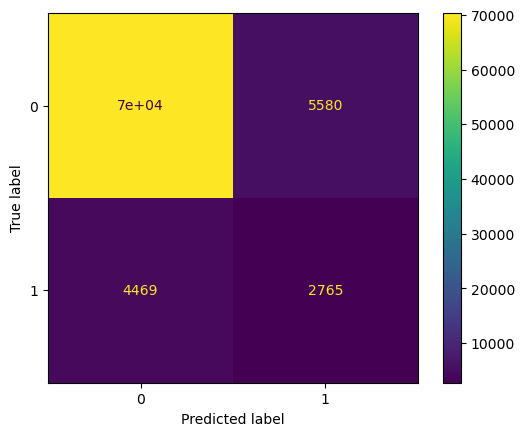

In [69]:
y_pred = cxgb2.predict(X_test)
conf_mat=confusion_matrix(y_test,y_pred)
cm_display = ConfusionMatrixDisplay(conf_mat).plot()
print(classification_report(y_test,y_pred))
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
specificity = tn / (tn + fp)
print("Especificidad:", specificity)

In [70]:
lgbm2 = LGBMClassifier(n_estimators = 10, min_samples_leaf = 15, max_depth = 15, random_state = 1, n_jobs = -1, 
                       learning_rate = 0.001, max_features = None)
lgbm2.fit(X_train_balanced, y_train_balanced)

[LightGBM] [Warning] min_data_in_leaf is set with min_child_samples=20, will be overridden by min_samples_leaf=15. Current value: min_data_in_leaf=15
[LightGBM] [Warning] Accuracy may be bad since you didn't explicitly set num_leaves OR 2^max_depth > num_leaves. (num_leaves=31).
[LightGBM] [Warning] min_data_in_leaf is set with min_child_samples=20, will be overridden by min_samples_leaf=15. Current value: min_data_in_leaf=15
[LightGBM] [Warning] Accuracy may be bad since you didn't explicitly set num_leaves OR 2^max_depth > num_leaves. (num_leaves=31).
[LightGBM] [Info] Number of positive: 305611, number of negative: 303621
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.028626 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4080
[LightGBM] [Info] Number of data points in the train set: 609232, number of used features: 16
[LightGBM] [I

LGBMClassifier(learning_rate=0.001, max_depth=15, max_features=None,
               min_samples_leaf=15, n_estimators=10, n_jobs=-1, random_state=1)

[LightGBM] [Warning] min_data_in_leaf is set with min_child_samples=20, will be overridden by min_samples_leaf=15. Current value: min_data_in_leaf=15
[LightGBM] [Warning] Accuracy may be bad since you didn't explicitly set num_leaves OR 2^max_depth > num_leaves. (num_leaves=31).
              precision    recall  f1-score   support

         0.0       0.95      0.87      0.90     75906
         1.0       0.26      0.49      0.34      7234

    accuracy                           0.83     83140
   macro avg       0.60      0.68      0.62     83140
weighted avg       0.89      0.83      0.86     83140

Especificidad: 0.8666640318288409


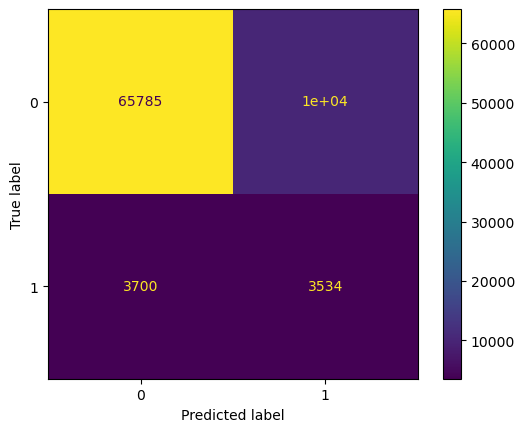

In [71]:
y_pred = lgbm2.predict(X_test)
conf_mat=confusion_matrix(y_test,y_pred)
cm_display = ConfusionMatrixDisplay(conf_mat).plot()
print(classification_report(y_test,y_pred))
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
specificity = tn / (tn + fp)
print("Especificidad:", specificity)

## Borderline SMOTE

In [72]:
from imblearn.over_sampling import BorderlineSMOTE

In [73]:
sm = BorderlineSMOTE(kind='borderline-1', k_neighbors=15, m_neighbors=21, random_state=42)
X_train_bls, y_train_bls = sm.fit_resample(X_train, y_train)

In [74]:
rfc4 = RandomForestClassifier(n_estimators = 50, max_leaf_nodes = 15, max_depth = 10, 
                             n_jobs=-1, random_state = 1)
rfc4.fit(X_train_bls, y_train_bls)

RandomForestClassifier(max_depth=10, max_leaf_nodes=15, n_estimators=50,
                       n_jobs=-1, random_state=1)

              precision    recall  f1-score   support

         0.0       0.95      0.88      0.91     75906
         1.0       0.29      0.51      0.37      7234

    accuracy                           0.85     83140
   macro avg       0.62      0.70      0.64     83140
weighted avg       0.89      0.85      0.87     83140

Especificidad: 0.8818275235159276


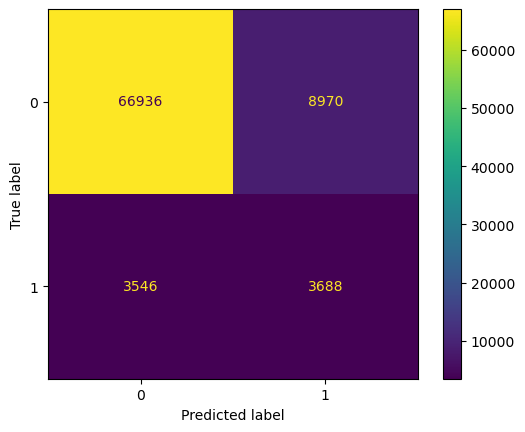

In [75]:
y_pred = rfc4.predict(X_test)
conf_mat=confusion_matrix(y_test,y_pred)
cm_display = ConfusionMatrixDisplay(conf_mat).plot()
print(classification_report(y_test,y_pred))
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
specificity = tn / (tn + fp)
print("Especificidad:", specificity)

In [76]:
from xgboost import XGBClassifier
cxgb4 = XGBClassifier(n_estimators = 10, min_samples_leaf = 20, max_depth = 15, random_state = 1, n_jobs = -1, 
                     learning_rate = 0.001)
cxgb4.fit(X_train_bls, y_train_bls)

C:\Users\alecv\anaconda3\envs\tf2\lib\site-packages\xgboost\core.py:160: UserWarning: [21:19:12] WARNING: C:\b\abs_0fh_d4x2ng\croot\xgboost-split_1713973188995\work\cpp_src\src\learner.cc:742: 
Parameters: { "min_samples_leaf" } are not used.

  warnings.warn(smsg, UserWarning)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.001, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=15, max_leaves=None,
              min_child_weight=None, min_samples_leaf=20, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=10,
              n_jobs=-1, num_parallel_tree=None, ...)

              precision    recall  f1-score   support

         0.0       0.92      0.98      0.95     75906
         1.0       0.42      0.14      0.21      7234

    accuracy                           0.91     83140
   macro avg       0.67      0.56      0.58     83140
weighted avg       0.88      0.91      0.89     83140

Especificidad: 0.9820567544067663


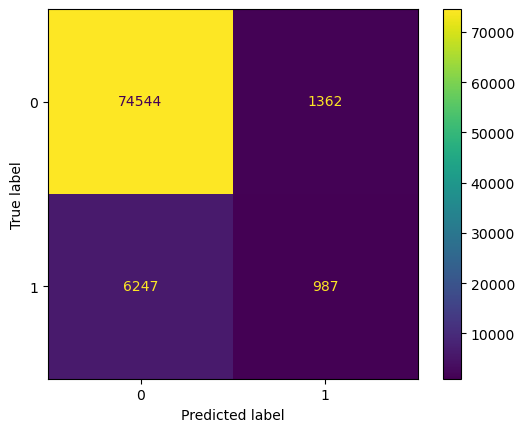

In [77]:
y_pred = cxgb4.predict(X_test)
conf_mat=confusion_matrix(y_test,y_pred)
cm_display = ConfusionMatrixDisplay(conf_mat).plot()
print(classification_report(y_test,y_pred))
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
specificity = tn / (tn + fp)
print("Especificidad:", specificity)

In [78]:
from lightgbm import LGBMClassifier
lgbm4 = LGBMClassifier(n_estimators = 10, min_samples_leaf = 20, max_depth = 15, random_state = 1, n_jobs = -1, 
                       learning_rate = 0.001)
lgbm4.fit(X_train_bls, y_train_bls)

[LightGBM] [Warning] min_data_in_leaf is set with min_child_samples=20, will be overridden by min_samples_leaf=20. Current value: min_data_in_leaf=20
[LightGBM] [Warning] Accuracy may be bad since you didn't explicitly set num_leaves OR 2^max_depth > num_leaves. (num_leaves=31).
[LightGBM] [Warning] min_data_in_leaf is set with min_child_samples=20, will be overridden by min_samples_leaf=20. Current value: min_data_in_leaf=20
[LightGBM] [Warning] Accuracy may be bad since you didn't explicitly set num_leaves OR 2^max_depth > num_leaves. (num_leaves=31).
[LightGBM] [Info] Number of positive: 303621, number of negative: 303621
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.028107 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4080
[LightGBM] [Info] Number of data points in the train set: 607242, number of used features: 16
[LightGBM] [I

LGBMClassifier(learning_rate=0.001, max_depth=15, min_samples_leaf=20,
               n_estimators=10, n_jobs=-1, random_state=1)

[LightGBM] [Warning] min_data_in_leaf is set with min_child_samples=20, will be overridden by min_samples_leaf=20. Current value: min_data_in_leaf=20
[LightGBM] [Warning] Accuracy may be bad since you didn't explicitly set num_leaves OR 2^max_depth > num_leaves. (num_leaves=31).
              precision    recall  f1-score   support

         0.0       0.93      0.95      0.94     75906
         1.0       0.34      0.24      0.28      7234

    accuracy                           0.89     83140
   macro avg       0.63      0.60      0.61     83140
weighted avg       0.88      0.89      0.88     83140

Especificidad: 0.9546412668300266


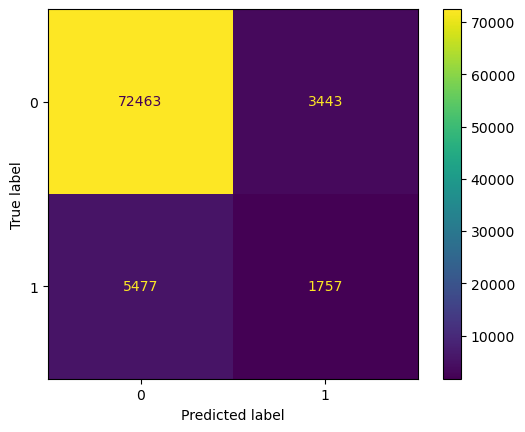

In [79]:
y_pred = lgbm4.predict(X_test)
conf_mat=confusion_matrix(y_test,y_pred)
cm_display = ConfusionMatrixDisplay(conf_mat).plot()
print(classification_report(y_test,y_pred))
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
specificity = tn / (tn + fp)
print("Especificidad:", specificity)